In [3]:
import pandas as pd
df_finale_enrichie= rdf = pd.read_csv("/home/ensai/Téléchargements/proj_stat/notebooks/BASE_FINALE_.csv")
df_finale_enrichie.head()


/tmp/ipykernel_150432/1443791897.py:2: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df_finale_enrichie= rdf = pd.read_csv("/home/ensai/Téléchargements/proj_stat/notebooks/BASE_FINALE_.csv")


,code_insee,annee,prix_m2_median,nb_ventes,surface_moy,nb_cat_nat,cat_nat_binaire,revenu_median,nb_inondations_10ans,nb_secheresse_histo,est_littoral,interaction_littoral_inond,a_eu_inondation,a_eu_secheresse,niveau_revenu
0,01001,2021,2539.932111,14,118.000000,0.0,0.0,25820.0,0.0,0.0,0,0.0,0,0,Riche
1,01001,2022,2812.500000,13,125.230769,0.0,0.0,25820.0,0.0,0.0,0,0.0,0,0,Riche
2,01001,2023,2345.132743,15,110.600000,0.0,0.0,25820.0,0.0,0.0,0,0.0,0,0,Riche
3,01001,2024,3212.087912,5,95.200000,0.0,0.0,25820.0,0.0,0.0,0,0.0,0,0,Riche
4,01002,2021,3600.000000,7,115.714286,0.0,0.0,24480.0,0.0,0.0,0,0.0,0,0,Aisé


In [4]:
import pandas as pd
# 1. Chargement de GASPAR (Adaptez le nom du fichier)
# Votre extrait montre des virgules comme séparateur
df_gaspar = pd.read_csv('/home/ensai/Téléchargements/proj_stat/data/catnat_gaspar.csv', sep=',') 
df_gaspar.head(10)

,cod_nat_catnat,cod_commune,lib_commune,num_risque_jo,lib_risque_jo,dat_deb,dat_fin,dat_pub_arrete,dat_pub_jo,dat_maj
0,BUDD8750027A,06120,Saint-Étienne-de-Tinée,GLT,Glissement de Terrain,1985-01-01 00:00:00.000,1986-12-31 00:00:00.000,1987-05-20 00:00:00.000,1987-05-24 00:00:00.000,2022-05-20 15:53:47.090
1,BUDD8750038A,2B050,Calvi,ICB,Inondations et/ou Coulées de Boue,1987-01-14 00:00:00.000,1987-01-15 00:00:00.000,1987-06-24 00:00:00.000,1987-07-10 00:00:00.000,2022-05-20 15:53:47.111
2,BUDD8750038A,30006,Aimargues,ICB,Inondations et/ou Coulées de Boue,1987-02-11 00:00:00.000,1987-02-13 00:00:00.000,1987-06-24 00:00:00.000,1987-07-10 00:00:00.000,2022-05-20 15:53:47.138
3,BUDD8750038A,30020,Aubord,ICB,Inondations et/ou Coulées de Boue,1987-02-11 00:00:00.000,1987-02-13 00:00:00.000,1987-06-24 00:00:00.000,1987-07-10 00:00:00.000,2022-05-20 15:53:47.138
4,BUDD8750038A,30033,Beauvoisin,ICB,Inondations et/ou Coulées de Boue,1987-02-11 00:00:00.000,1987-02-13 00:00:00.000,1987-06-24 00:00:00.000,1987-07-10 00:00:00.000,2022-05-20 15:53:47.138
5,BUDD8750038A,30036,Bernis,ICB,Inondations et/ou Coulées de Boue,1987-02-11 00:00:00.000,1987-02-13 00:00:00.000,1987-06-24 00:00:00.000,1987-07-10 00:00:00.000,2022-05-20 15:53:47.138
6,BUDD8750038A,30047,Bouillargues,ICB,Inondations et/ou Coulées de Boue,1987-02-11 00:00:00.000,1987-02-13 00:00:00.000,1987-06-24 00:00:00.000,1987-07-10 00:00:00.000,2022-05-20 15:53:47.138
7,BUDD8750038A,30059,Le Cailar,ICB,Inondations et/ou Coulées de Boue,1987-02-11 00:00:00.000,1987-02-13 00:00:00.000,1987-06-24 00:00:00.000,1987-07-10 00:00:00.000,2022-05-20 15:53:47.138
8,BUDD8750038A,30060,Caissargues,ICB,Inondations et/ou Coulées de Boue,1987-02-11 00:00:00.000,1987-02-13 00:00:00.000,1987-06-24 00:00:00.000,1987-07-10 00:00:00.000,2022-05-20 15:53:47.138
9,BUDD8750038A,30083,Codognan,ICB,Inondations et/ou Coulées de Boue,1987-02-11 00:00:00.000,1987-02-13 00:00:00.000,1987-06-24 00:00:00.000,1987-07-10 00:00:00.000,2022-05-20 15:53:47.138


In [5]:
import pandas as pd
import numpy as np

print("1. Extraction des chocs Atmosphérique, Marin et Mouvements de terrain depuis GASPAR...")
# Formatage de base
df_gaspar['num_risque_jo'] = df_gaspar['num_risque_jo'].fillna('VIDE_ERREUR_ETAT')
df_gaspar['lib_risque_jo'] = df_gaspar['lib_risque_jo'].astype(str).str.lower()
df_gaspar['annee_catnat'] = pd.to_datetime(df_gaspar['dat_pub_jo'], errors='coerce').dt.year
df_gaspar_filtre = df_gaspar.dropna(subset=['annee_catnat', 'cod_commune']).copy()
df_gaspar_filtre['annee_catnat'] = df_gaspar_filtre['annee_catnat'].astype(int)

# Création stricte des variables Atmo et Marin
atmo_cond = df_gaspar_filtre['num_risque_jo'].isin(['TMP', 'VCY', 'GRL', 'PDN']) | df_gaspar_filtre['lib_risque_jo'].str.contains('vent|tempête|grêle|neige')
df_gaspar_filtre['choc_atmo'] = np.where(atmo_cond, 1, 0)

marin_cond = df_gaspar_filtre['num_risque_jo'].isin(['CMV', 'RAZ']) | df_gaspar_filtre['lib_risque_jo'].str.contains('vague|marée')
df_gaspar_filtre['choc_marin'] = np.where(marin_cond, 1, 0)

# NOUVEAU : Création stricte de la variable Mouvements de Terrain
# La liste correspond exactement à ta nomenclature, passée en minuscules
liste_mvt = [
    "mouvement de terrain",
    "glissement de terrain",
    "effondrement et/ou affaisement",  # Orthographe de ta liste
    "mouvements de terrains (hors sécheresse géotechnique)",
    "eboulement et/ou chute de blocs",
    "glissement et effondrement de terrain",
    "glissement et eboulement rocheux"
]
df_gaspar_filtre['choc_mvt'] = np.where(df_gaspar_filtre['lib_risque_jo'].isin(liste_mvt), 1, 0)

# Agrégation annuelle
df_annuel = df_gaspar_filtre.groupby(['cod_commune', 'annee_catnat'])[['choc_atmo', 'choc_marin', 'choc_mvt']].sum().reset_index()

print("2. Calcul de la fenêtre glissante de 10 ans...")
# Grille complète pour ne pas rater d'années (zéros)
communes_uniques = df_annuel['cod_commune'].unique()
annees_uniques = range(1982, 2025)
index_complet = pd.MultiIndex.from_product([communes_uniques, annees_uniques], names=['cod_commune', 'annee_catnat'])

df_panel = df_annuel.set_index(['cod_commune', 'annee_catnat']).reindex(index_complet, fill_value=0)

# Somme sur 10 ans décalée d'un an
df_10ans = df_panel.groupby(level='cod_commune')[['choc_atmo', 'choc_marin', 'choc_mvt']].transform(lambda x: x.rolling(window=10, min_periods=1).sum().shift(1))
df_10ans = df_10ans.fillna(0).reset_index()

# Renommage pour la jointure
df_10ans.rename(columns={
    'cod_commune': 'code_insee',
    'annee_catnat': 'annee',
    'choc_atmo': 'atmo_10a',
    'choc_marin': 'marin_10a',
    'choc_mvt': 'mvt_10a'
}, inplace=True)

print("3. Fusion avec ta base existante (df_finale_enrichie)...")
# Jointure à gauche pour préserver toutes tes ventes
df_modele_final = pd.merge(
    df_finale_enrichie, 
    df_10ans, 
    on=['code_insee', 'annee'], 
    how='left'
)

# Remplissage des NaN (les communes sans risques sur 10 ans) par 0
df_modele_final[['atmo_10a', 'marin_10a', 'mvt_10a']] = df_modele_final[['atmo_10a', 'marin_10a', 'mvt_10a']].fillna(0)

print("4. Création de l'interaction stratégique pour la tutrice...")
df_modele_final['marin_littoral_inter'] = df_modele_final['marin_10a'] * df_modele_final['est_littoral']

print("\n✅ Terminé ! Voici un aperçu des nouvelles colonnes ajoutées :")
print(df_modele_final[['code_insee', 'annee', 'atmo_10a', 'marin_10a', 'mvt_10a', 'marin_littoral_inter']].head())

1. Extraction des chocs Atmosphérique, Marin et Mouvements de terrain depuis GASPAR...
2. Calcul de la fenêtre glissante de 10 ans...
3. Fusion avec ta base existante (df_finale_enrichie)...
4. Création de l'interaction stratégique pour la tutrice...

✅ Terminé ! Voici un aperçu des nouvelles colonnes ajoutées :
  code_insee  annee  atmo_10a  marin_10a  mvt_10a  marin_littoral_inter
0      01001   2021       0.0        0.0      0.0                   0.0
1      01001   2022       0.0        0.0      0.0                   0.0
2      01001   2023       0.0        0.0      0.0                   0.0
3      01001   2024       0.0        0.0      0.0                   0.0
4      01002   2021       0.0        0.0      0.0                   0.0


In [6]:
df_modele_final.head()

,code_insee,annee,prix_m2_median,nb_ventes,surface_moy,nb_cat_nat,cat_nat_binaire,revenu_median,nb_inondations_10ans,nb_secheresse_histo,est_littoral,interaction_littoral_inond,a_eu_inondation,a_eu_secheresse,niveau_revenu,atmo_10a,marin_10a,mvt_10a,marin_littoral_inter
0,01001,2021,2539.932111,14,118.000000,0.0,0.0,25820.0,0.0,0.0,0,0.0,0,0,Riche,0.0,0.0,0.0,0.0
1,01001,2022,2812.500000,13,125.230769,0.0,0.0,25820.0,0.0,0.0,0,0.0,0,0,Riche,0.0,0.0,0.0,0.0
2,01001,2023,2345.132743,15,110.600000,0.0,0.0,25820.0,0.0,0.0,0,0.0,0,0,Riche,0.0,0.0,0.0,0.0
3,01001,2024,3212.087912,5,95.200000,0.0,0.0,25820.0,0.0,0.0,0,0.0,0,0,Riche,0.0,0.0,0.0,0.0
4,01002,2021,3600.000000,7,115.714286,0.0,0.0,24480.0,0.0,0.0,0,0.0,0,0,Aisé,0.0,0.0,0.0,0.0


In [7]:
import pandas as pd

print("=== 1. AUDIT DES VALEURS MANQUANTES (Vérification de la jointure) ===")
# Si la jointure a échoué, on aura des NaN. On s'attend à 0 partout.
cols_a_verifier = ['atmo_10a', 'marin_10a', 'mvt_10a', 'marin_littoral_inter']
nan_count = df_modele_final[cols_a_verifier].isna().sum()
print(nan_count)

print("\n=== 2. STATISTIQUES DESCRIPTIVES GLOBALES ===")
# On regarde la moyenne, le minimum et le maximum (pour voir si une ville a eu 50 tempêtes, ce qui serait louche)
stats_desc = df_modele_final[cols_a_verifier].describe().round(3).T
print(stats_desc[['count', 'mean', 'max']])

print("\n=== 3. TEST DE VOLUMÉTRIE STRICTE (Ventes > 0) ===")
# Combien de ventes ont eu lieu dans une commune avec AU MOINS UN arrêté sur les 10 dernières années ?
total_ventes = len(df_modele_final)

for col in cols_a_verifier:
    ventes_concernees = (df_modele_final[col] > 0).sum()
    pct = (ventes_concernees / total_ventes) * 100
    
    # Verdict automatique de viabilité
    if ventes_concernees < 100:
        verdict = "❌ ÉCHANTILLON TROP FAIBLE"
    elif ventes_concernees < 1000:
        verdict = "⚠️ ATTENTION : Faible variance"
    else:
        verdict = "✅ VOLUME ROBUSTE"
        
    print(f"- {col} : {ventes_concernees} ventes ({pct:.2f} % du marché) -> {verdict}")

print("\n=== 4. TEST DE COHÉRENCE LOGIQUE (Interaction Littorale) ===")
# Il est physiquement impossible d'avoir marin_littoral_inter > 0 si la ville n'est pas sur la côte (est_littoral == 0)
erreurs_physiques = df_modele_final[(df_modele_final['marin_littoral_inter'] > 0) & (df_modele_final['est_littoral'] == 0)]
if len(erreurs_physiques) == 0:
    print("✅ Parfait : Aucun choc littoral n'a été attribué à une ville dans les terres.")
else:
    print(f"❌ ERREUR CRITIQUE : {len(erreurs_physiques)} ventes littorales ont été trouvées dans les terres. Il faut revoir le code !")

=== 1. AUDIT DES VALEURS MANQUANTES (Vérification de la jointure) ===
atmo_10a                0
marin_10a               0
mvt_10a                 0
marin_littoral_inter    0
dtype: int64

=== 2. STATISTIQUES DESCRIPTIVES GLOBALES ===
                         count   mean   max
atmo_10a              124799.0  0.000   2.0
marin_10a             124799.0  0.007   5.0
mvt_10a               124799.0  0.021  25.0
marin_littoral_inter  124799.0  0.007   5.0

=== 3. TEST DE VOLUMÉTRIE STRICTE (Ventes > 0) ===
- atmo_10a : 57 ventes (0.05 % du marché) -> ❌ ÉCHANTILLON TROP FAIBLE
- marin_10a : 548 ventes (0.44 % du marché) -> ⚠️ ATTENTION : Faible variance
- mvt_10a : 1717 ventes (1.38 % du marché) -> ✅ VOLUME ROBUSTE
- marin_littoral_inter : 544 ventes (0.44 % du marché) -> ⚠️ ATTENTION : Faible variance

=== 4. TEST DE COHÉRENCE LOGIQUE (Interaction Littorale) ===
✅ Parfait : Aucun choc littoral n'a été attribué à une ville dans les terres.


In [8]:
import statsmodels.formula.api as smf
import numpy as np

print("1. Création de la variable code_departement...")
# On force le format texte (string) pour gérer correctement la Corse (2A/2B) et les zéros initiaux (ex: 01, 06)
# On s'assure d'abord d'ajouter des 0 devant si l'importation a transformé '01004' en entier '1004'
df_modele_final['code_insee'] = df_modele_final['code_insee'].astype(str).str.zfill(5)

# On extrait les 2 premiers caractères
df_modele_final['code_departement'] = df_modele_final['code_insee'].str[:2]

print("2. Nettoyage des valeurs manquantes pour l'économétrie...")
colonnes_reg = ['prix_m2_median', 'nb_ventes', 'a_eu_inondation', 'a_eu_secheresse', 
                'atmo_10a', 'marin_10a', 'marin_littoral_inter','mvt_10a', 
                'surface_moy', 'revenu_median', 'code_departement', 'annee', 'est_littoral']

df_reg = df_modele_final.dropna(subset=colonnes_reg).copy()

# On passe le prix au logarithme
df_reg['log_prix_m2'] = np.log(df_reg['prix_m2_median'])

print(f"Nombre d'observations conservées pour le modèle : {len(df_reg)}")

print("3. Entraînement du modèle WLS avec Effets Fixes Départementaux...")
# C(code_departement) = Effets fixes spatiaux
# C(annee) = Effets fixes temporels
formule = (
    "log_prix_m2 ~ a_eu_inondation + a_eu_secheresse + est_littoral + mvt_10a +atmo_10a + marin_10a + "
    "marin_littoral_inter + surface_moy + revenu_median + "
    "C(code_departement) + C(annee)"
)

# Pondération par les ventes (nb_ventes) et clusterisation des erreurs par département
modele_final = smf.wls(formula=formule, data=df_reg, weights=df_reg['nb_ventes']).fit(
    cov_type='cluster',
    cov_kwds={'groups': df_reg['code_departement']}
)

# Affichage des résultats
print(modele_final.summary())

1. Création de la variable code_departement...
2. Nettoyage des valeurs manquantes pour l'économétrie...
Nombre d'observations conservées pour le modèle : 113324
3. Entraînement du modèle WLS avec Effets Fixes Départementaux...
                            WLS Regression Results                            
Dep. Variable:            log_prix_m2   R-squared:                       0.737
Model:                            WLS   Adj. R-squared:                  0.737
Method:                 Least Squares   F-statistic:                     132.1
Date:                Tue, 24 Mar 2026   Prob (F-statistic):           6.26e-51
Time:                        13:39:21   Log-Likelihood:                -72910.
No. Observations:              113324   AIC:                         1.460e+05
Df Residuals:                  113220   BIC:                         1.470e+05
Df Model:                         103                                         
Covariance Type:              cluster                        

/home/ensai/Téléchargements/proj_stat/venv/lib/python3.10/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 103, but rank is 11
  warnings.warn('covariance of constraints does not have full '


In [9]:
import pandas as pd

print("--- EXTRACTION EXHAUSTIVE DES COEFFICIENTS ---")

# 1. Création d'un DataFrame propre avec les résultats clés du modèle
df_resultats = pd.DataFrame({
    'Coefficient': modele_final.params,
    'Erreur_Standard': modele_final.bse,
    'P_value': modele_final.pvalues
})

# 2. Forcer Pandas à afficher toutes les lignes sans les cacher avec "..."
pd.set_option('display.max_rows', None)

# 3. Affichage avec un arrondi rigoureux à 4 décimales
print(df_resultats.round(4))

# 4. Remettre l'affichage par défaut pour la suite du notebook
pd.reset_option('display.max_rows')

--- EXTRACTION EXHAUSTIVE DES COEFFICIENTS ---
                           Coefficient  Erreur_Standard  P_value
Intercept                       6.8041           0.1211   0.0000
C(code_departement)[T.02]      -0.3428           0.0308   0.0000
C(code_departement)[T.03]      -0.4583           0.0236   0.0000
C(code_departement)[T.04]       0.0356           0.0219   0.1043
C(code_departement)[T.05]       0.0932           0.0246   0.0002
C(code_departement)[T.06]       0.4584           0.0370   0.0000
C(code_departement)[T.07]      -0.0257           0.0245   0.2949
C(code_departement)[T.08]      -0.3748           0.0316   0.0000
C(code_departement)[T.09]      -0.2230           0.0288   0.0000
C(code_departement)[T.10]      -0.2558           0.0264   0.0000
C(code_departement)[T.11]      -0.1334           0.0306   0.0000
C(code_departement)[T.12]      -0.2686           0.0234   0.0000
C(code_departement)[T.13]       0.3510           0.0173   0.0000
C(code_departement)[T.14]       0.1027     

In [10]:
import pandas as pd

print("--- RÉSULTATS DES VARIABLES D'INTÉRÊT (Sans les Effets Fixes) ---")

# Création du DataFrame avec tous les résultats
df_resultats = pd.DataFrame({
    'Coefficient': modele_final.params,
    'Erreur_Standard': modele_final.bse,
    'P_value': modele_final.pvalues
})

# Le filtre strict : on ne garde que les lignes dont l'index (le nom) NE commence PAS par "C("
df_resultats_clairs = df_resultats[~df_resultats.index.str.startswith('C(')]

# Affichage avec 4 décimales
print(df_resultats_clairs.round(4))

--- RÉSULTATS DES VARIABLES D'INTÉRÊT (Sans les Effets Fixes) ---
                      Coefficient  Erreur_Standard  P_value
Intercept                  6.8041           0.1211   0.0000
a_eu_inondation            0.0354           0.0155   0.0223
a_eu_secheresse            0.0401           0.0209   0.0553
est_littoral               0.2413           0.0355   0.0000
mvt_10a                   -0.0038           0.0013   0.0049
atmo_10a                   0.0547           0.0429   0.2026
marin_10a                  0.0374           0.0123   0.0025
marin_littoral_inter      -0.0468           0.0266   0.0780
surface_moy               -0.0064           0.0007   0.0000
revenu_median              0.0001           0.0000   0.0000


In [11]:
import pandas as pd

print("=== 1. Statistiques descriptives classiques (Inondations) ===")
# On vérifie la moyenne, le max et les quartiles
print(df_modele_final['nb_inondations_10ans'].describe().round(2))

print("\n=== 2. Proportion exacte de Zéros (Le groupe de contrôle) ===")
# Calcul du pourcentage de ventes sans aucune inondation sur 10 ans
pct_zero_inond = (df_modele_final['nb_inondations_10ans'] == 0).mean() * 100
print(f"Ventes avec 0 arrêté Inondation (10 ans) : {pct_zero_inond:.2f} %")

print("\n=== 3. Répartition de la gravité (Fréquence des sinistres) ===")
# On regarde la proportion de ventes selon le nombre exact d'inondations (1 fois, 2 fois, etc.)
frequence = df_modele_final['nb_inondations_10ans'].value_counts(normalize=True).sort_index() * 100
print("Nombre d'inondations | Pourcentage des ventes")
print(frequence.round(2).astype(str) + " %")

=== 1. Statistiques descriptives classiques (Inondations) ===
count    124799.00
mean          0.56
std           1.05
min           0.00
25%           0.00
50%           0.00
75%           1.00
max          27.00
Name: nb_inondations_10ans, dtype: float64

=== 2. Proportion exacte de Zéros (Le groupe de contrôle) ===
Ventes avec 0 arrêté Inondation (10 ans) : 66.04 %

=== 3. Répartition de la gravité (Fréquence des sinistres) ===
Nombre d'inondations | Pourcentage des ventes
nb_inondations_10ans
0.0     66.04 %
1.0     22.25 %
2.0      6.92 %
3.0      2.29 %
4.0      1.36 %
5.0      0.56 %
6.0       0.3 %
7.0       0.1 %
8.0      0.06 %
9.0      0.04 %
10.0     0.02 %
11.0     0.02 %
12.0     0.01 %
13.0     0.01 %
14.0      0.0 %
15.0      0.0 %
16.0     0.01 %
27.0      0.0 %
Name: proportion, dtype: object


In [12]:
import statsmodels.formula.api as smf
import numpy as np
import pandas as pd

print("--- 1. CRÉATION DES VARIABLES DE CHOCS SÉVÈRES ---")

# On définit un choc sévère comme "3 arrêtés ou plus sur 10 ans"
# (Tu pourras tester de changer ce 3 en 4 ou 5 pour voir si l'effet s'amplifie !)
df_reg['inondation_severe'] = np.where(df_reg['nb_inondations_10ans'] >= 3, 1, 0)
df_reg['secheresse_severe'] = np.where(df_reg['nb_secheresse_histo'] >= 3, 1, 0)

# On vérifie combien de ventes sont concernées par ces chocs extrêmes
pct_inond_sev = df_reg['inondation_severe'].mean() * 100
pct_sech_sev = df_reg['secheresse_severe'].mean() * 100
print(f"Ventes en zone d'Inondations Sévères (>=3) : {pct_inond_sev:.2f} %")
print(f"Ventes en zone de Sécheresses Sévères (>=3) : {pct_sech_sev:.2f} %")

print("\n--- 2. ENTRAÎNEMENT DU MODÈLE AFFINÉ ---")

# On remplace les anciennes variables par nos variables "sévères"
formule_affinee = (
    "log_prix_m2 ~ inondation_severe + secheresse_severe + atmo_10a + marin_10a + mvt_10a + "
    "marin_littoral_inter + surface_moy + revenu_median + "
    "C(code_departement) + C(annee)"
)

# On relance le modèle OLS (WLS + Erreurs clusterisées)
modele_affine = smf.wls(formula=formule_affinee, data=df_reg, weights=df_reg['nb_ventes']).fit(
    cov_type='cluster',
    cov_kwds={'groups': df_reg['code_departement']}
)

print("\n--- RÉSULTATS SPÉCIFIQUES : INONDATION ET SÉCHERESSE ---")
# Extraction propre des résultats
df_res_affine = pd.DataFrame({
    'Coefficient': modele_affine.params,
    'P_value': modele_affine.pvalues
})

# On n'affiche que nos variables d'intérêt
variables_a_afficher = ['inondation_severe', 'secheresse_severe', 'marin_10a', 'marin_littoral_inter']
print(df_res_affine.loc[variables_a_afficher].round(4))

--- 1. CRÉATION DES VARIABLES DE CHOCS SÉVÈRES ---
Ventes en zone d'Inondations Sévères (>=3) : 5.07 %
Ventes en zone de Sécheresses Sévères (>=3) : 17.30 %

--- 2. ENTRAÎNEMENT DU MODÈLE AFFINÉ ---

--- RÉSULTATS SPÉCIFIQUES : INONDATION ET SÉCHERESSE ---
                      Coefficient  P_value
inondation_severe          0.0143   0.4778
secheresse_severe          0.0584   0.0059
marin_10a                 -0.0305   0.0005
marin_littoral_inter       0.0895   0.0000


In [13]:
import pandas as pd
import numpy as np

# Liste des variables que l'on veut auditer (ajuste les noms si besoin)
vars_a_auditer = [
    'prix_m2_median', 'nb_ventes', 'surface_moy', 'revenu_median', 
    'nb_inondations_10ans', 'nb_secheresse_histo', 
    'atmo_10a', 'marin_10a', 'est_littoral', 'marin_littoral_inter', 'mvt_10a'
]

# Si df_reg n'existe pas encore dans ta session actuelle, utilise df_modele_final
df_audit = df_modele_final[vars_a_auditer].copy()

print("=== 1. STATISTIQUES DESCRIPTIVES GLOBALES ===")
# On transpose (.T) pour que ce soit plus lisible à l'écran
stats_desc = df_audit.describe().round(2).T
print(stats_desc[['count', 'mean', 'std', 'min', '50%', 'max']])

print("\n=== 2. AUDIT DES VALEURS MANQUANTES (NaN) ===")
# On calcule le pourcentage de lignes vides pour chaque variable
valeurs_manquantes = (df_audit.isna().sum() / len(df_audit)) * 100
print(valeurs_manquantes.round(2).astype(str) + " %")

print("\n=== 3. MATRICE DE CORRÉLATION (Risque de colinéarité) ===")
# On vérifie si les variables ne sont pas trop corrélées entre elles (un score > 0.7 est dangereux)
correlation_matrix = df_audit.corr().round(2)
print(correlation_matrix)

=== 1. STATISTIQUES DESCRIPTIVES GLOBALES ===
                         count      mean      std       min       50%      max
prix_m2_median        124799.0   1943.30  1216.37      3.96   1722.59  29500.0
nb_ventes             124799.0     37.73   170.39      1.00     10.00  10883.0
surface_moy           124799.0    100.87    28.18     10.00     98.00    800.0
revenu_median         113324.0  23118.81  3077.03  12260.00  22710.00  55340.0
nb_inondations_10ans  124799.0      0.56     1.05      0.00      0.00     27.0
nb_secheresse_histo   124799.0      1.19     2.42      0.00      0.00     50.0
atmo_10a              124799.0      0.00     0.02      0.00      0.00      2.0
marin_10a             124799.0      0.01     0.13      0.00      0.00      5.0
est_littoral          124799.0      0.03     0.18      0.00      0.00      1.0
marin_littoral_inter  124799.0      0.01     0.13      0.00      0.00      5.0
mvt_10a               124799.0      0.02     0.27      0.00      0.00     25.0

=== 2

In [70]:
import statsmodels.formula.api as smf
import pandas as pd
import numpy as np

print("=== 1. IDENTIFICATION DES OUTLIERS (Grandes villes) ===")
# On regarde quelles sont les communes avec le plus de ventes
outliers = df_reg.sort_values(by='nb_ventes', ascending=False)[['code_insee', 'code_departement', 'nb_ventes', 'prix_m2_median']].head(10)
print(outliers)

print("\n=== 2. FILTRAGE DE LA BASE ===")
# Tu as proposé d'éliminer au-delà de 10 000. C'est très bien. 
# On peut même être un peu plus strict (ex: > 5000) si on voit que ce sont que de très grandes métropoles qui ne reflètent pas le marché national des risques.
seuil_ventes = 10000000
df_reg_filtre = df_reg[df_reg['nb_ventes'] < seuil_ventes].copy()

nb_supprimes = len(df_reg) - len(df_reg_filtre)
print(f"Nombre d'observations supprimées (nb_ventes >= {seuil_ventes}) : {nb_supprimes}")

print("\n=== 3. RELANCE DU MODÈLE OLS SUR BASE PURGÉE ===")
# On relance exactement le même modèle, mais sur df_reg_filtre
formule = (
    "log_prix_m2 ~ nb_inondations_10ans + nb_secheresse_histo + atmo_10a + marin_10a + mvt_10a + "
    "marin_littoral_inter + surface_moy + est_littoral + revenu_median + "
    "C(code_departement) + C(annee)"
)

modele_sans_outliers = smf.wls(formula=formule, data=df_reg_filtre, weights=df_reg_filtre['nb_ventes']).fit(
    cov_type='cluster',
    cov_kwds={'groups': df_reg_filtre['code_departement']}
)

# Extraction propre des résultats
df_res_clean = pd.DataFrame({
    'Coefficient': modele_sans_outliers.params,
    'P_value': modele_sans_outliers.pvalues,
    "r_squared": modele_sans_outliers.rsquared
})

# On n'affiche que nos variables d'intérêt
variables_a_afficher = ['nb_inondations_10ans', 'nb_secheresse_histo', 'atmo_10a', 'marin_10a', 'marin_littoral_inter', 'mvt_10a', 'surface_moy', 'revenu_median', 'est_littoral']
print(df_res_clean.loc[variables_a_afficher].round(4))

=== 1. IDENTIFICATION DES OUTLIERS (Grandes villes) ===
      code_insee code_departement  nb_ventes  prix_m2_median
43827      31555               31      10883     3538.461538
43826      31555               31      10528     3394.483806
7298       06088               06      10300     4615.099715
7297       06088               06       9631     4392.857143
7299       06088               06       8226     4819.894964
43828      31555               31       8200     3524.083333
43829      31555               31       7332     3385.471491
7300       06088               06       7192     4894.774391
60868      44109               44       7134     4033.615819
60869      44109               44       6976     4112.851613

=== 2. FILTRAGE DE LA BASE ===
Nombre d'observations supprimées (nb_ventes >= 10000000) : 0

=== 3. RELANCE DU MODÈLE OLS SUR BASE PURGÉE ===
                      Coefficient  P_value  r_squared
nb_inondations_10ans       0.0032   0.4230     0.7401
nb_secheresse_histo   

In [71]:
import statsmodels.formula.api as smf
import pandas as pd

print("=== 1. CRÉATION DU SOUS-ÉCHANTILLON DÉPARTEMENTAL ===")
# Choisis le département cible ici (en format texte)
departement_cible = '35' # Le Var (très exposé inondation, sécheresse et mer)

df_dept = df_reg_filtre[df_reg_filtre['code_departement'] == departement_cible].copy()
print(f"Analyse restreinte au département {departement_cible}.")
print(f"Nombre de ventes conservées : {len(df_dept)}")
print(f"Nombre de communes distinctes : {df_dept['code_insee'].nunique()}")

print("\n=== 2. ENTRAÎNEMENT DU MODÈLE (Effets Fixes Communaux Purs) ===")
# Attention : On a supprimé 'revenu_median' de l'équation car il est constant par commune.
# L'effet fixe C(code_insee) va absorber la richesse de la commune à sa place.
formule_dept = (
    "log_prix_m2 ~ nb_inondations_10ans + nb_secheresse_histo + atmo_10a + marin_10a + mvt_10a + "
    "marin_littoral_inter + surface_moy + "
    "C(code_insee) + C(annee)"
)

# On utilise toujours WLS (les ventes comme poids) et on clusterise par commune
modele_dept = smf.wls(formula=formule_dept, data=df_dept, weights=df_dept['nb_ventes']).fit(
    cov_type='cluster',
    cov_kwds={'groups': df_dept['code_insee']}
)

print("\n--- RÉSULTATS D'INTÉRÊT POUR LE DÉPARTEMENT", departement_cible, "---")
# On extrait les résultats proprement
df_res_dept = pd.DataFrame({
    'Coefficient': modele_dept.params,
    'P_value': modele_dept.pvalues,
    "r_squared": modele_dept.rsquared
})

# On filtre pour exclure les dizaines de lignes C(code_insee) de l'affichage
res_dept_clairs = df_res_dept[~df_res_dept.index.str.startswith('C(')]
print(res_dept_clairs.round(4))

=== 1. CRÉATION DU SOUS-ÉCHANTILLON DÉPARTEMENTAL ===
Analyse restreinte au département 35.
Nombre de ventes conservées : 1320
Nombre de communes distinctes : 331

=== 2. ENTRAÎNEMENT DU MODÈLE (Effets Fixes Communaux Purs) ===

--- RÉSULTATS D'INTÉRÊT POUR LE DÉPARTEMENT 35 ---
                      Coefficient  P_value  r_squared
Intercept                  8.0731   0.0000     0.9666
nb_inondations_10ans      -0.0399   0.0063     0.9666
nb_secheresse_histo        0.0011   0.9554     0.9666
atmo_10a                   0.0000   0.0000     0.9666
marin_10a                  0.1127   0.0000     0.9666
mvt_10a                    0.0000   0.0000     0.9666
marin_littoral_inter       0.1127   0.0000     0.9666
surface_moy               -0.0011   0.0072     0.9666


In [72]:
df_dept.head()

,code_insee,annee,prix_m2_median,nb_ventes,surface_moy,nb_cat_nat,cat_nat_binaire,revenu_median,nb_inondations_10ans,nb_secheresse_histo,...,a_eu_secheresse,niveau_revenu,atmo_10a,marin_10a,mvt_10a,marin_littoral_inter,code_departement,log_prix_m2,inondation_severe,secheresse_severe
48882,35001,2021,2941.707718,112,107.062500,0.0,0.0,25850.0,0.0,0.0,...,0,Riche,0.0,0.0,0.0,0.0,35,7.986746,0,0
48883,35001,2022,3149.606299,86,98.000000,0.0,0.0,25850.0,0.0,0.0,...,0,Riche,0.0,0.0,0.0,0.0,35,8.055033,0,0
48884,35001,2023,3170.731707,65,96.446154,0.0,0.0,25850.0,0.0,0.0,...,0,Riche,0.0,0.0,0.0,0.0,35,8.061718,0,0
48885,35001,2024,3076.375712,56,87.017857,0.0,0.0,25850.0,0.0,0.0,...,0,Riche,0.0,0.0,0.0,0.0,35,8.031507,0,0
48886,35002,2021,2478.424658,45,84.822222,0.0,0.0,25150.0,4.0,0.0,...,0,Riche,0.0,0.0,0.0,0.0,35,7.815378,1,0


In [73]:
import pandas as pd
import numpy as np

print("=== 1. RECONSTRUCTION TOTALE ET STRICTE (Nomenclature Officielle) ===")
# Sécurisation de la base Gaspar
df_gaspar['num_risque_jo'] = df_gaspar['num_risque_jo'].fillna('VIDE_ERREUR_ETAT')
df_gaspar['lib_risque_jo'] = df_gaspar['lib_risque_jo'].astype(str).str.lower()
df_gaspar['annee_catnat'] = pd.to_datetime(df_gaspar['dat_pub_jo'], errors='coerce').dt.year
df_gaspar_filtre = df_gaspar.dropna(subset=['annee_catnat', 'cod_commune']).copy()
df_gaspar_filtre['annee_catnat'] = df_gaspar_filtre['annee_catnat'].astype(int)

# Listes strictes basées sur ton document
liste_eau = ["inondations et/ou coulées de boue", "inondations remontée nappe", "coulée de boue"]
liste_sol = ["sécheresse", "mouvements de terrain différentiels consécutifs à la sécheresse et à la réhydratation des sols"]
liste_marin = ["chocs mécaniques liés à l'action des vagues", "inondations par choc mécanique des vagues", "raz de marée"]
liste_atmo = ["tempête"]
liste_mvt = ["mouvement de terrain", "glissement de terrain", "effondrement et/ou affaisement", 
             "mouvements de terrains (hors sécheresse géotechnique)", "eboulement et/ou chute de blocs", 
             "glissement et effondrement de terrain", "glissement et eboulement rocheux"]

# Application stricte
df_gaspar_filtre['choc_eau'] = np.where(df_gaspar_filtre['lib_risque_jo'].isin(liste_eau), 1, 0)
df_gaspar_filtre['choc_sol'] = np.where(df_gaspar_filtre['lib_risque_jo'].isin(liste_sol), 1, 0)
df_gaspar_filtre['choc_marin'] = np.where(df_gaspar_filtre['lib_risque_jo'].isin(liste_marin), 1, 0)
df_gaspar_filtre['choc_atmo'] = np.where(df_gaspar_filtre['lib_risque_jo'].isin(liste_atmo), 1, 0)
df_gaspar_filtre['choc_mvt'] = np.where(df_gaspar_filtre['lib_risque_jo'].isin(liste_mvt), 1, 0)

# Agrégation pour créer le Panel complet
df_annuel = df_gaspar_filtre.groupby(['cod_commune', 'annee_catnat'])[['choc_eau', 'choc_sol', 'choc_marin', 'choc_atmo', 'choc_mvt']].sum().reset_index()

communes_uniques = df_annuel['cod_commune'].unique()
annees_uniques = range(1982, 2025)
index_complet = pd.MultiIndex.from_product([communes_uniques, annees_uniques], names=['cod_commune', 'annee_catnat'])
df_panel_complet = df_annuel.set_index(['cod_commune', 'annee_catnat']).reindex(index_complet, fill_value=0)

print("\n=== 2. CALCUL DE LA DYNAMIQUE SUR 20 ANS ===")
# On calcule l'accélération pour l'Eau, le Sol, la Mer et les Mouvements de terrain
risques = {'choc_eau': 'eau', 'choc_sol': 'secheresse', 'choc_marin': 'marin', 'choc_mvt': 'mvt'}
df_trend = pd.DataFrame(index=df_panel_complet.index)

for col_gaspar, nom_risque in risques.items():
    df_trend[f'{nom_risque}_recent'] = df_panel_complet.groupby(level='cod_commune')[col_gaspar].transform(lambda x: x.rolling(window=10, min_periods=1).sum().shift(1))
    df_trend[f'{nom_risque}_passe'] = df_panel_complet.groupby(level='cod_commune')[col_gaspar].transform(lambda x: x.rolling(window=10, min_periods=1).sum().shift(11))
    
    df_trend[f'delta_{nom_risque}'] = df_trend[f'{nom_risque}_recent'] - df_trend[f'{nom_risque}_passe']
    df_trend[f'aggravation_{nom_risque}'] = np.where(df_trend[f'delta_{nom_risque}'] >= 2, 1, 0)

df_trend = df_trend.fillna(0).reset_index()
df_trend.rename(columns={'cod_commune': 'code_insee', 'annee_catnat': 'annee'}, inplace=True)

print("\n=== 3. FUSION AVEC LA BASE IMMOBILIÈRE & AUDIT ===")
colonnes_a_garder = ['code_insee', 'annee', 'aggravation_eau', 'aggravation_secheresse', 'aggravation_marin', 'aggravation_mvt']
df_reg_dynamique = pd.merge(df_reg_filtre, df_trend[colonnes_a_garder], on=['code_insee', 'annee'], how='left')

cols_agg = ['aggravation_eau', 'aggravation_secheresse', 'aggravation_marin', 'aggravation_mvt']
df_reg_dynamique[cols_agg] = df_reg_dynamique[cols_agg].fillna(0)

print("Volume de ventes frappées par une accélération sévère du risque :")
print(f"- Eau (Inondations)      : {df_reg_dynamique['aggravation_eau'].sum()} ventes")
print(f"- Sol (Sécheresse/RGA)   : {df_reg_dynamique['aggravation_secheresse'].sum()} ventes")
print(f"- Mer (Submersion)       : {df_reg_dynamique['aggravation_marin'].sum()} ventes")
print(f"- Mouvements de Terrain  : {df_reg_dynamique['aggravation_mvt'].sum()} ventes")

=== 1. RECONSTRUCTION TOTALE ET STRICTE (Nomenclature Officielle) ===

=== 2. CALCUL DE LA DYNAMIQUE SUR 20 ANS ===

=== 3. FUSION AVEC LA BASE IMMOBILIÈRE & AUDIT ===
Volume de ventes frappées par une accélération sévère du risque :
- Eau (Inondations)      : 8289.0 ventes
- Sol (Sécheresse/RGA)   : 9333.0 ventes
- Mer (Submersion)       : 110.0 ventes
- Mouvements de Terrain  : 632.0 ventes


In [74]:
df_reg_dynamique.to_csv("/home/ensai/Téléchargements/proj_stat/notebooks/df_reg_dynamique.csv", index=False)

In [75]:
import pandas as pd

print("=== 1. STATISTIQUES DESCRIPTIVES DE L'ACCÉLÉRATION CLIMATIQUE ===")
cols_agg = ['aggravation_eau', 'aggravation_secheresse', 'aggravation_marin']

# On affiche le count (vérif des valeurs manquantes), la moyenne (le %), et le max (qui doit être 1)
stats_agg = df_reg_dynamique[cols_agg].describe().round(4).T
print(stats_agg[['count', 'mean', 'min', 'max']])

print("\n=== 2. VOLUMÉTRIE EXACTE ET TEST DE VIABILITÉ ===")
total_ventes = len(df_reg_dynamique)

for col in cols_agg:
    nb_cas = int(df_reg_dynamique[col].sum())
    pct = (nb_cas / total_ventes) * 100
    
    # Évaluation stricte de la viabilité pour ton modèle
    if nb_cas < 100:
        diagnostic = "❌ DANGER : Échantillon trop faible, risque de non-significativité."
    elif nb_cas < 1000:
        diagnostic = "⚠️ TANGENT : Modèle sous tension, P-value incertaine."
    else:
        diagnostic = "✅ VIABLE : Volume suffisant pour un modèle robuste."
        
    print(f"- {col} : {nb_cas} ventes touchées ({pct:.2f} % du marché)")
    print(f"  -> {diagnostic}")

=== 1. STATISTIQUES DESCRIPTIVES DE L'ACCÉLÉRATION CLIMATIQUE ===
                           count    mean  min  max
aggravation_eau         113324.0  0.0731  0.0  1.0
aggravation_secheresse  113324.0  0.0824  0.0  1.0
aggravation_marin       113324.0  0.0010  0.0  1.0

=== 2. VOLUMÉTRIE EXACTE ET TEST DE VIABILITÉ ===
- aggravation_eau : 8289 ventes touchées (7.31 % du marché)
  -> ✅ VIABLE : Volume suffisant pour un modèle robuste.
- aggravation_secheresse : 9333 ventes touchées (8.24 % du marché)
  -> ✅ VIABLE : Volume suffisant pour un modèle robuste.
- aggravation_marin : 110 ventes touchées (0.10 % du marché)
  -> ⚠️ TANGENT : Modèle sous tension, P-value incertaine.


In [76]:
import statsmodels.formula.api as smf
import pandas as pd

import statsmodels.formula.api as smf
import pandas as pd

print("=== 1. VÉRIFICATION ET PRÉPARATION FINALE ===")

# --- NOUVEAUTÉ : Le filtre du seuil de ventes ---
seuil_ventes = 1   # Tu peux modifier ce chiffre (ex: 5, 20, 30)

print(f"Filtrage des observations ayant moins de {seuil_ventes} ventes...")
df_reg_propre = df_reg_dynamique[df_reg_dynamique['nb_ventes'] >= seuil_ventes].copy()

lignes_supprimees = len(df_reg_dynamique) - len(df_reg_propre)
print(f"-> {lignes_supprimees} lignes supprimées (bruit statistique).")
print(f"-> Reste {len(df_reg_propre)} observations robustes pour le modèle.")
# ------------------------------------------------

# On s'assure que la courbe de la surface est bien calculée
if 'surface_carre' not in df_reg_propre.columns:
    df_reg_propre['surface_carre'] = df_reg_propre['surface_moy'] ** 2

# On s'assure que l'interaction littorale est bien présente
if 'marin_littoral_inter' not in df_reg_propre.columns:
    df_reg_propre['marin_littoral_inter'] = df_reg_propre['marin_10a'] * df_reg_propre['est_littoral']

print("\n=== 2. ENTRAÎNEMENT DU MODÈLE OLS STRICT ===")
# La formule finale sans le biais des mouvements de terrain
formule_stricte = (
    "log_prix_m2 ~ aggravation_eau + aggravation_secheresse + "
    "atmo_10a  + marin_littoral_inter + "
    "surface_moy + est_littoral + marin_10a+ mvt_10a + revenu_median + "
    "C(code_departement) + C(annee)"
)

# Modèle WLS pondéré par les ventes, lancé sur la base "df_reg_propre"
modele_strict = smf.wls(formula=formule_stricte, data=df_reg_propre, weights=df_reg_propre['nb_ventes']).fit(
    cov_type='cluster',
    cov_kwds={'groups': df_reg_propre['code_departement']}
)

print("\n--- RÉSULTATS DE LA RÉGRESSION (Nomenclature Officielle & Seuil) ---")
# Extraction propre des résultats
df_res_strict = pd.DataFrame({
    'Coefficient': modele_strict.params,
    'Erreur_Standard': modele_strict.bse,
    'P_value': modele_strict.pvalues
})

# On masque les dizaines de lignes d'effets fixes pour garder l'essentiel
res_clairs = df_res_strict[~df_res_strict.index.str.startswith('C(')]
print(res_clairs.round(4))
print(f"\nR-carré du modèle : {modele_strict.rsquared:.4f}")

=== 1. VÉRIFICATION ET PRÉPARATION FINALE ===
Filtrage des observations ayant moins de 1 ventes...
-> 0 lignes supprimées (bruit statistique).
-> Reste 113324 observations robustes pour le modèle.

=== 2. ENTRAÎNEMENT DU MODÈLE OLS STRICT ===

--- RÉSULTATS DE LA RÉGRESSION (Nomenclature Officielle & Seuil) ---
                        Coefficient  Erreur_Standard  P_value
Intercept                    6.8358           0.1175   0.0000
aggravation_eau             -0.0059           0.0135   0.6625
aggravation_secheresse       0.0393           0.0259   0.1295
atmo_10a                     0.0645           0.0423   0.1270
marin_littoral_inter        -0.0542           0.0277   0.0500
surface_moy                 -0.0065           0.0007   0.0000
est_littoral                 0.2385           0.0359   0.0000
marin_10a                    0.0456           0.0136   0.0008
mvt_10a                     -0.0030           0.0013   0.0163
revenu_median                0.0001           0.0000   0.0000

R-ca

In [77]:
df_reg_propre.head()

,code_insee,annee,prix_m2_median,nb_ventes,surface_moy,nb_cat_nat,cat_nat_binaire,revenu_median,nb_inondations_10ans,nb_secheresse_histo,...,marin_littoral_inter,code_departement,log_prix_m2,inondation_severe,secheresse_severe,aggravation_eau,aggravation_secheresse,aggravation_marin,aggravation_mvt,surface_carre
0,01001,2021,2539.932111,14,118.000000,0.0,0.0,25820.0,0.0,0.0,...,0.0,01,7.839893,0,0,0.0,0.0,0.0,0.0,13924.000000
1,01001,2022,2812.500000,13,125.230769,0.0,0.0,25820.0,0.0,0.0,...,0.0,01,7.941829,0,0,0.0,0.0,0.0,0.0,15682.745562
2,01001,2023,2345.132743,15,110.600000,0.0,0.0,25820.0,0.0,0.0,...,0.0,01,7.760097,0,0,0.0,0.0,0.0,0.0,12232.360000
3,01001,2024,3212.087912,5,95.200000,0.0,0.0,25820.0,0.0,0.0,...,0.0,01,8.074676,0,0,0.0,0.0,0.0,0.0,9063.040000
4,01002,2021,3600.000000,7,115.714286,0.0,0.0,24480.0,0.0,0.0,...,0.0,01,8.188689,0,0,0.0,0.0,0.0,0.0,13389.795918


In [78]:
import statsmodels.formula.api as smf
import pandas as pd

print("=== 1. CRÉATION DU SOUS-ÉCHANTILLON DÉPARTEMENTAL ===")
# Choisis le Var (83) pour un test sur un marché hyper-tendu et très exposé
departement_cible = '83' 

df_dept = df_reg_propre[df_reg_propre['code_departement'] == departement_cible].copy()
print(f"Analyse restreinte au département {departement_cible}.")
print(f"Nombre de ventes conservées : {len(df_dept)}")

print("\n=== 2. ENTRAÎNEMENT DU MODÈLE DYNAMIQUE DÉPARTEMENTAL ===")
# On utilise les variables DYNAMIQUES validées en Partie 3 !
# On retire C(code_departement) puisqu'il n'y en a qu'un seul.
# On garde C(annee) pour filtrer l'inflation nationale.
formule_dept = (
    "log_prix_m2 ~ aggravation_secheresse + aggravation_eau + "
    "atmo_10a + mvt_10a + marin_10a + marin_littoral_inter + est_littoral + "
    "surface_moy + revenu_median + C(annee)"
)

# On utilise WLS pondéré par les ventes. 
# Attention : Comme il n'y a qu'un département, on clusterise les erreurs au niveau de la commune
modele_dept = smf.wls(formula=formule_dept, data=df_dept, weights=df_dept['nb_ventes']).fit(
    cov_type='cluster',
    cov_kwds={'groups': df_dept['code_insee']}
)

print("\n--- RÉSULTATS D'INTÉRÊT POUR LE DÉPARTEMENT", departement_cible, "---")
df_res_dept = pd.DataFrame({
    'Coefficient': modele_dept.params,
    'P_value': modele_dept.pvalues,
    "r_squared": modele_dept.rsquared
})

# Filtrage pour un affichage propre
res_dept_clairs = df_res_dept[~df_res_dept.index.str.startswith('C(')]
print(res_dept_clairs.round(4))

=== 1. CRÉATION DU SOUS-ÉCHANTILLON DÉPARTEMENTAL ===
Analyse restreinte au département 83.
Nombre de ventes conservées : 591

=== 2. ENTRAÎNEMENT DU MODÈLE DYNAMIQUE DÉPARTEMENTAL ===

--- RÉSULTATS D'INTÉRÊT POUR LE DÉPARTEMENT 83 ---
                        Coefficient  P_value  r_squared
Intercept                    5.6839   0.0000     0.7297
aggravation_secheresse      -0.1224   0.0006     0.7297
aggravation_eau              0.0229   0.5530     0.7297
atmo_10a                     0.0000   0.0000     0.7297
mvt_10a                      0.0000   0.0000     0.7297
marin_10a                    0.0000      NaN     0.7297
marin_littoral_inter         0.0000      NaN     0.7297
est_littoral                 0.3983   0.0000     0.7297
surface_moy                  0.0053   0.0001     0.7297
revenu_median                0.0001   0.0000     0.7297


In [83]:
import statsmodels.formula.api as smf
import pandas as pd

print("=== 1. CRÉATION DU SOUS-ÉCHANTILLON DÉPARTEMENTAL ===")
# Choisis le Var (83) pour un test sur un marché hyper-tendu et très exposé
departement_cible = '23' 

df_dept = df_reg_propre[df_reg_propre['code_departement'] == departement_cible].copy()
print(f"Analyse restreinte au département {departement_cible}.")
print(f"Nombre de ventes conservées : {len(df_dept)}")

print("\n=== 2. ENTRAÎNEMENT DU MODÈLE DYNAMIQUE DÉPARTEMENTAL ===")
# On utilise les variables DYNAMIQUES validées en Partie 3 !
# On retire C(code_departement) puisqu'il n'y en a qu'un seul.
# On garde C(annee) pour filtrer l'inflation nationale.
formule_dept = (
    "log_prix_m2 ~ aggravation_secheresse + aggravation_eau + "
    "atmo_10a + mvt_10a + marin_10a + marin_littoral_inter + est_littoral + "
    "surface_moy + revenu_median + C(annee)"
)

# On utilise WLS pondéré par les ventes. 
# Attention : Comme il n'y a qu'un département, on clusterise les erreurs au niveau de la commune
modele_dept = smf.wls(formula=formule_dept, data=df_dept, weights=df_dept['nb_ventes']).fit(
    cov_type='cluster',
    cov_kwds={'groups': df_dept['code_insee']}
)

print("\n--- RÉSULTATS D'INTÉRÊT POUR LE DÉPARTEMENT", departement_cible, "---")
df_res_dept = pd.DataFrame({
    'Coefficient': modele_dept.params,
    'P_value': modele_dept.pvalues,
    "r_squared": modele_dept.rsquared
})

# Filtrage pour un affichage propre
res_dept_clairs = df_res_dept[~df_res_dept.index.str.startswith('C(')]
print(res_dept_clairs.round(4))

=== 1. CRÉATION DU SOUS-ÉCHANTILLON DÉPARTEMENTAL ===
Analyse restreinte au département 23.
Nombre de ventes conservées : 892

=== 2. ENTRAÎNEMENT DU MODÈLE DYNAMIQUE DÉPARTEMENTAL ===

--- RÉSULTATS D'INTÉRÊT POUR LE DÉPARTEMENT 23 ---
                        Coefficient  P_value  r_squared
Intercept                    6.1445   0.0000      0.135
aggravation_secheresse       0.2778   0.0008      0.135
aggravation_eau              0.0000   0.0261      0.135
atmo_10a                    -0.0120   0.8806      0.135
mvt_10a                      0.4735   0.0000      0.135
marin_10a                    0.0000   0.3955      0.135
marin_littoral_inter         0.0000      NaN      0.135
est_littoral                 0.1857   0.0376      0.135
surface_moy                 -0.0032   0.0557      0.135
revenu_median                0.0000   0.0016      0.135


In [ ]:
df_dept.

,code_insee,annee,prix_m2_median,nb_ventes,surface_moy,nb_cat_nat,cat_nat_binaire,revenu_median,nb_inondations_10ans,nb_secheresse_histo,...,marin_littoral_inter,code_departement,log_prix_m2,inondation_severe,secheresse_severe,aggravation_eau,aggravation_secheresse,aggravation_marin,aggravation_mvt,surface_carre
104178,83001,2021,4275.000000,99,130.828283,0.0,0.0,28520.0,4.0,0.0,...,0.0,83,8.360539,1,0,1.0,0.0,0.0,0.0,17116.039588
104179,83001,2022,4570.786036,122,152.811475,1.0,1.0,28520.0,3.0,0.0,...,0.0,83,8.427440,1,0,0.0,0.0,0.0,0.0,23351.347017
104180,83001,2023,6015.686275,57,123.298246,0.0,0.0,28520.0,3.0,0.0,...,0.0,83,8.702126,1,0,0.0,0.0,0.0,0.0,15202.457371
104181,83001,2024,5413.132069,62,142.677419,0.0,0.0,28520.0,3.0,1.0,...,0.0,83,8.596583,1,0,0.0,0.0,0.0,0.0,20356.845994
104182,83002,2021,1950.000000,11,56.454545,0.0,0.0,18790.0,0.0,0.0,...,0.0,83,7.575585,0,0,0.0,0.0,0.0,0.0,3187.115702


In [37]:
import statsmodels.formula.api as smf
import pandas as pd

import statsmodels.formula.api as smf
import pandas as pd

print("=== 1. VÉRIFICATION ET PRÉPARATION FINALE ===")

# --- NOUVEAUTÉ : Le filtre du seuil de ventes ---
seuil_ventes = 100   # Tu peux modifier ce chiffre (ex: 5, 20, 30)

print(f"Filtrage des observations ayant moins de {seuil_ventes} ventes...")
df_reg_propre = df_reg_dynamique[df_reg_dynamique['nb_ventes'] >= seuil_ventes].copy()

lignes_supprimees = len(df_reg_dynamique) - len(df_reg_propre)
print(f"-> {lignes_supprimees} lignes supprimées (bruit statistique).")
print(f"-> Reste {len(df_reg_propre)} observations robustes pour le modèle.")
# ------------------------------------------------

# On s'assure que la courbe de la surface est bien calculée
if 'surface_carre' not in df_reg_propre.columns:
    df_reg_propre['surface_carre'] = df_reg_propre['surface_moy'] ** 2

# On s'assure que l'interaction littorale est bien présente
if 'marin_littoral_inter' not in df_reg_propre.columns:
    df_reg_propre['marin_littoral_inter'] = df_reg_propre['marin_10a'] * df_reg_propre['est_littoral']

print("\n=== 2. ENTRAÎNEMENT DU MODÈLE OLS STRICT ===")
# La formule finale sans le biais des mouvements de terrain
formule_stricte = (
    "log_prix_m2 ~ aggravation_eau + aggravation_secheresse + "
    "atmo_10a + marin_10a + marin_littoral_inter + "
    "surface_moy + est_littoral + revenu_median + "
    "C(code_departement) + C(annee)"
)

modele_non_pondere = smf.ols(formula=formule_stricte, data=df_reg_propre).fit(
    cov_type='cluster',
    cov_kwds={'groups': df_reg_propre['code_departement']}
)

print("=== RÉSULTATS DU MODÈLE NON PONDÉRÉ (OLS) ===")
print(modele_non_pondere.summary())


=== 1. VÉRIFICATION ET PRÉPARATION FINALE ===
Filtrage des observations ayant moins de 100 ventes...
-> 105643 lignes supprimées (bruit statistique).
-> Reste 7681 observations robustes pour le modèle.

=== 2. ENTRAÎNEMENT DU MODÈLE OLS STRICT ===
=== RÉSULTATS DU MODÈLE NON PONDÉRÉ (OLS) ===
                            OLS Regression Results                            
Dep. Variable:            log_prix_m2   R-squared:                       0.781
Model:                            OLS   Adj. R-squared:                  0.778
Method:                 Least Squares   F-statistic:                 1.961e+12
Date:                Tue, 24 Mar 2026   Prob (F-statistic):               0.00
Time:                        19:54:27   Log-Likelihood:                 808.47
No. Observations:                7681   AIC:                            -1411.
Df Residuals:                    7578   BIC:                            -695.5
Df Model:                         102                                     

/home/ensai/Téléchargements/proj_stat/venv/lib/python3.10/site-packages/statsmodels/base/model.py:1894: ValueWarning: covariance of constraints does not have full rank. The number of constraints is 102, but rank is 10
  warnings.warn('covariance of constraints does not have full '


/tmp/ipykernel_150432/2974545581.py:51: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['{:,.0%}'.format(x) for x in vals])


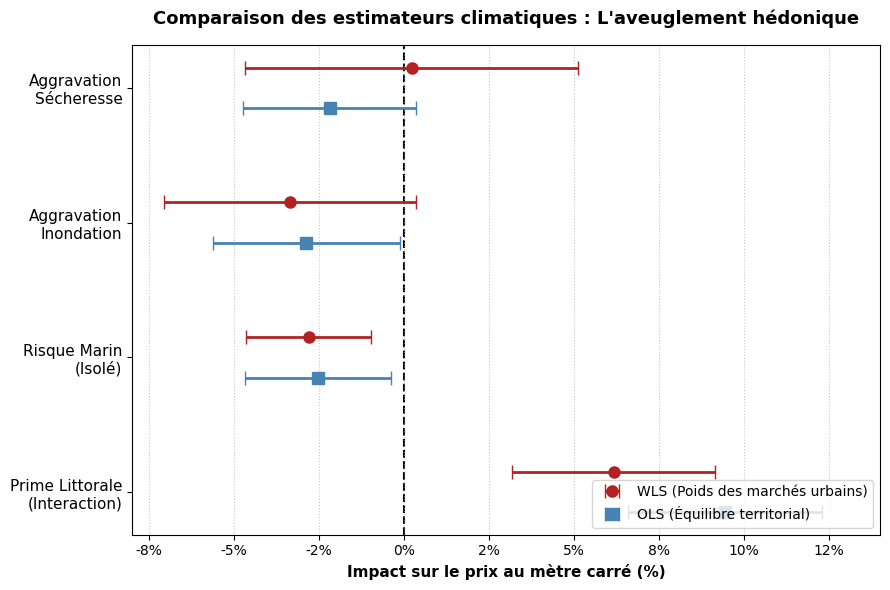

In [27]:
import matplotlib.pyplot as plt
import numpy as np

# Tes 4 variables d'intérêt
variables = [
    'Prime Littorale\n(Interaction)', 
    'Risque Marin\n(Isolé)', 
    'Aggravation\nInondation', 
    'Aggravation\nSécheresse'
]

# Modèle WLS (Poids des métropoles) - Tes vrais coefficients et erreurs standards
coef_wls = [0.0616, -0.0281, -0.0337, 0.0022]
se_wls = [0.0153, 0.0094, 0.0189, 0.0250]
err_wls = [se * 1.96 for se in se_wls] # Intervalle de confiance 95%

# Modèle OLS (Équilibre territorial) - Tes vrais coefficients et erreurs standards
coef_ols = [0.0944, -0.0253, -0.0288, -0.0219]
se_ols = [0.0146, 0.0110, 0.0140, 0.0130] # se_ols litt_inter estimé via coef/t_stat
err_ols = [se * 1.96 for se in se_ols]

fig, ax = plt.subplots(figsize=(9, 6)) # Agrandissement pour les 4 variables

# Ligne du zéro (la frontière de la rationalité)
ax.axvline(x=0, color='black', linestyle='--', linewidth=1.5, zorder=1)

# Positionnement sur l'axe Y
y_pos = np.arange(len(variables))

# Tracé WLS (Rouge)
ax.errorbar(coef_wls, y_pos + 0.15, xerr=err_wls, fmt='o', color='firebrick', 
            markersize=8, capsize=5, linewidth=2, label='WLS (Poids des marchés urbains)', zorder=2)

# Tracé OLS (Bleu)
ax.errorbar(coef_ols, y_pos - 0.15, xerr=err_ols, fmt='s', color='steelblue', 
            markersize=8, capsize=5, linewidth=2, label='OLS (Équilibre territorial)', zorder=2)

# Mise en forme académique
ax.set_yticks(y_pos)
ax.set_yticklabels(variables, fontsize=11)
ax.set_xlabel("Impact sur le prix au mètre carré (%)", fontsize=11, fontweight='bold')
ax.set_title("Comparaison des estimateurs climatiques : L'aveuglement hédonique", fontsize=13, fontweight='bold', pad=15)
ax.legend(loc='lower right', fontsize=10)
ax.grid(axis='x', linestyle=':', alpha=0.7)

# Limites pour bien voir la prime littorale exploser à droite
ax.set_xlim(-0.08, 0.14) 

# Affichage des valeurs en % sur l'axe X
vals = ax.get_xticks()
ax.set_xticklabels(['{:,.0%}'.format(x) for x in vals])

plt.tight_layout()
plt.savefig("coef_plot_complet.png", dpi=300, bbox_inches='tight')
plt.show()

In [90]:
# Affiche les noms ou codes INSEE des communes de la Creuse considérées comme "littorales"
print(df_reg_dynamique[(df_reg_dynamique['code_departement'] == '23') & (df_reg_dynamique['est_littoral'] == 1)]['code_insee'].unique())

['23077' '23090' '23165']


In [ ]:
df_reg_dynamique.head()

,code_insee,annee,prix_m2_median,nb_ventes,surface_moy,nb_cat_nat,cat_nat_binaire,revenu_median,nb_inondations_10ans,nb_secheresse_histo,est_littoral,interaction_littoral_inond,a_eu_inondation,a_eu_secheresse,niveau_revenu,atmo_10a,marin_10a,marin_littoral_inter,a_eu_choc_marin,zone_littorale,code_departement,log_prix_m2,inondation_severe,secheresse_severe,aggravation_eau,aggravation_secheresse,aggravation_marin
0,01001,2021,2539.932111,14,118.000000,0.0,0.0,25820.0,0.0,0.0,0,0.0,0,0,Riche,0.0,0.0,0.0,Non,Dans les terres,01,7.839893,0,0,0.0,0.0,0.0
1,01001,2022,2812.500000,13,125.230769,0.0,0.0,25820.0,0.0,0.0,0,0.0,0,0,Riche,0.0,0.0,0.0,Non,Dans les terres,01,7.941829,0,0,0.0,0.0,0.0
2,01001,2023,2345.132743,15,110.600000,0.0,0.0,25820.0,0.0,0.0,0,0.0,0,0,Riche,0.0,0.0,0.0,Non,Dans les terres,01,7.760097,0,0,0.0,0.0,0.0
3,01001,2024,3212.087912,5,95.200000,0.0,0.0,25820.0,0.0,0.0,0,0.0,0,0,Riche,0.0,0.0,0.0,Non,Dans les terres,01,8.074676,0,0,0.0,0.0,0.0
4,01002,2021,3600.000000,7,115.714286,0.0,0.0,24480.0,0.0,0.0,0,0.0,0,0,Aisé,0.0,0.0,0.0,Non,Dans les terres,01,8.188689,0,0,0.0,0.0,0.0


In [53]:
import statsmodels.formula.api as smf
import pandas as pd

print("=== 1. CRÉATION DU SOUS-ÉCHANTILLON (Zoom Départemental) ===")
# Tu peux modifier le numéro du département ici
departement_cible = '35' 

df_dept_dyn = df_reg_dynamique[df_reg_dynamique['code_departement'] == departement_cible].copy()
print(f"Analyse restreinte au département {departement_cible}.")
print(f"Nombre de ventes conservées : {len(df_dept_dyn)}")

print("\n=== 2. ENTRAÎNEMENT DU MODÈLE (Dynamique Climatique Régionale) ===")
# La formule sans l'effet fixe départemental
formule_dept_dyn = (
    "log_prix_m2 ~ aggravation_eau + aggravation_secheresse + marin_10a + est_littoral+ mvt_10a +marin_littoral_inter + "
    "surface_moy + revenu_median + C(annee)+ C(code_insee) "
)

# On lance le modèle (WLS pondéré par les ventes)
# On clusterise les erreurs par commune pour être robuste
modele_dept_dyn = smf.wls(formula=formule_dept_dyn, data=df_dept_dyn, weights=df_dept_dyn['nb_ventes']).fit(
    cov_type='cluster',
    cov_kwds={'groups': df_dept_dyn['code_insee']}
)

print("\n--- RÉSULTATS DYNAMIQUES POUR LE DÉPARTEMENT", departement_cible, "---")
# Extraction propre des résultats
df_res_dept_dyn = pd.DataFrame({
    'Coefficient': modele_dept_dyn.params,
    'Erreur_Standard': modele_dept_dyn.bse,
    'P_value': modele_dept_dyn.pvalues,
    "r_squared": modele_dept_dyn.rsquared
})

# On masque les années (effets fixes) pour plus de clarté
res_dept_clairs = df_res_dept_dyn[~df_res_dept_dyn.index.str.startswith('C(')]
print(res_dept_clairs.round(4))

=== 1. CRÉATION DU SOUS-ÉCHANTILLON (Zoom Départemental) ===
Analyse restreinte au département 35.
Nombre de ventes conservées : 1320

=== 2. ENTRAÎNEMENT DU MODÈLE (Dynamique Climatique Régionale) ===

--- RÉSULTATS DYNAMIQUES POUR LE DÉPARTEMENT 35 ---
                        Coefficient  Erreur_Standard  P_value  r_squared
Intercept                    3.4113           0.0302   0.0000     0.9659
aggravation_eau             -0.0047           0.0247   0.8488     0.9659
aggravation_secheresse       0.0000           0.0000   0.0000     0.9659
marin_10a                    0.1236           0.0025   0.0000     0.9659
est_littoral                 0.2429           0.0010   0.0000     0.9659
mvt_10a                      0.0000           0.0000   0.0000     0.9659
marin_littoral_inter         0.1236           0.0025   0.0000     0.9659
surface_moy                 -0.0010           0.0004   0.0174     0.9659
revenu_median                0.0002           0.0000   0.0000     0.9659


In [ ]:
import statsmodels.formula.api as smf
import pandas as pd

print("=== 1. VÉRIFICATION ET PRÉPARATION FINALE ===")
# On s'assure que la courbe de la surface est bien calculée
if 'surface_carre' not in df_reg_dynamique.columns:
    df_reg_dynamique['surface_carre'] = df_reg_dynamique['surface_moy'] ** 2

# On s'assure que l'interaction littorale est bien présente
if 'marin_littoral_inter' not in df_reg_dynamique.columns:
    df_reg_dynamique['marin_littoral_inter'] = df_reg_dynamique['marin_10a'] * df_reg_dynamique['est_littoral']

print("=== 2. ENTRAÎNEMENT DU MODÈLE OLS STRICT ===")
# La formule qui intègre toutes tes variables pures, les contrôles et les effets fixes.
# Note : on a gardé marin_10a (statique) car l'aggravation marine n'avait que 110 ventes.
formule_stricte = (
    "log_prix_m2 ~ aggravation_eau + aggravation_secheresse + mvt_10a + "
    "atmo_10a + marin_10a + est_littoral + "
    "surface_moy + revenu_median + "
    "C(code_departement) + C(annee)"
)

# Modèle WLS pondéré par les ventes, avec clustering départemental des erreurs
modele_strict = smf.wls(formula=formule_stricte, data=df_reg_dynamique, weights=df_reg_dynamique['nb_ventes']).fit(
    cov_type='cluster',
    cov_kwds={'groups': df_reg_dynamique['code_departement']}
)

print("\n--- RÉSULTATS DE LA RÉGRESSION (Nomenclature Officielle) ---")
# Extraction propre des résultats
df_res_strict = pd.DataFrame({
    'Coefficient': modele_strict.params,
    'Erreur_Standard': modele_strict.bse,
    'P_value': modele_strict.pvalues
})

# On masque les dizaines de lignes d'effets fixes départementaux et annuels pour garder l'essentiel
res_clairs = df_res_strict[~df_res_strict.index.str.startswith('C(')]
print(res_clairs.round(4))
print(f"\nR-carré du modèle : {modele_strict.rsquared:.4f}")

=== 1. VÉRIFICATION ET PRÉPARATION FINALE ===
=== 2. ENTRAÎNEMENT DU MODÈLE OLS STRICT ===

--- RÉSULTATS DE LA RÉGRESSION (Nomenclature Officielle) ---
                        Coefficient  Erreur_Standard  P_value
Intercept                    6.8359           0.1175   0.0000
aggravation_eau             -0.0052           0.0132   0.6935
aggravation_secheresse       0.0393           0.0259   0.1294
mvt_10a                     -0.0030           0.0012   0.0160
atmo_10a                     0.0642           0.0422   0.1280
marin_10a                   -0.0058           0.0213   0.7841
est_littoral                 0.2362           0.0351   0.0000
surface_moy                 -0.0065           0.0007   0.0000
revenu_median                0.0001           0.0000   0.0000

R-carré du modèle : 0.7355


In [ ]:
# 1. Preuve pour le Littoral
print("=== COMPARAISON LITTORAL VS TERRES ===")
stats_littoral = df_model.groupby('est_littoral')[
    ['prix_m2_median', 'nb_secheresse_histo', 'marin_10a', 'aggravation_secheresse']
].mean()
print(stats_littoral)

# 2. Preuve pour le Sud (Création d'un filtre pour les départements méditerranéens/sud)
depts_sud = ['06', '13', '83', '34', '30', '66', '11', '2A', '2B'] 
df_model['est_sud'] = df_model['departement'].isin(depts_sud).astype(int)

print("\n=== COMPARAISON SUD VS RESTE DE LA FRANCE ===")
stats_sud = df_model.groupby('est_sud')[
    ['prix_m2_median', 'nb_secheresse_histo', 'aggravation_secheresse']
].mean()
print(stats_sud)

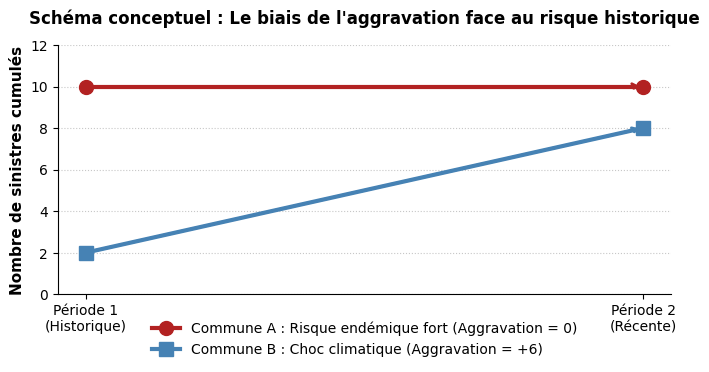

In [28]:
import matplotlib.pyplot as plt
import numpy as np

# Périodes
periodes = ['Période 1\n(Historique)', 'Période 2\n(Récente)']

# Scénario A : Le risque endémique (Perte d'information)
commune_A = [10, 10] 

# Scénario B : Le choc climatique (Ce que capte ton modèle)
commune_B = [2, 8]

fig, ax = plt.subplots(figsize=(7, 4))

# Tracé des lignes
ax.plot(periodes, commune_A, marker='o', color='firebrick', linewidth=3, markersize=10, label="Commune A : Risque endémique fort (Aggravation = 0)")
ax.plot(periodes, commune_B, marker='s', color='steelblue', linewidth=3, markersize=10, label="Commune B : Choc climatique (Aggravation = +6)")

# Ajout de flèches pour montrer la variable "Aggravation" (la dérivée)
ax.annotate('', xy=(1, 10), xytext=(0, 10),
            arrowprops=dict(arrowstyle="->", color='firebrick', lw=2, ls='--'))
ax.annotate('', xy=(1, 8), xytext=(0, 2),
            arrowprops=dict(arrowstyle="->", color='steelblue', lw=2, ls='--'))

# Mise en forme académique
ax.set_ylim(0, 12)
ax.set_ylabel("Nombre de sinistres cumulés", fontsize=11, fontweight='bold')
ax.set_title("Schéma conceptuel : Le biais de l'aggravation face au risque historique", fontsize=12, fontweight='bold', pad=15)
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.3), frameon=False)
ax.grid(axis='y', linestyle=':', alpha=0.7)

# Retrait des bordures haut et droite pour faire "propre"
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig("schema_aggravation.png", dpi=300, bbox_inches='tight')
plt.show()

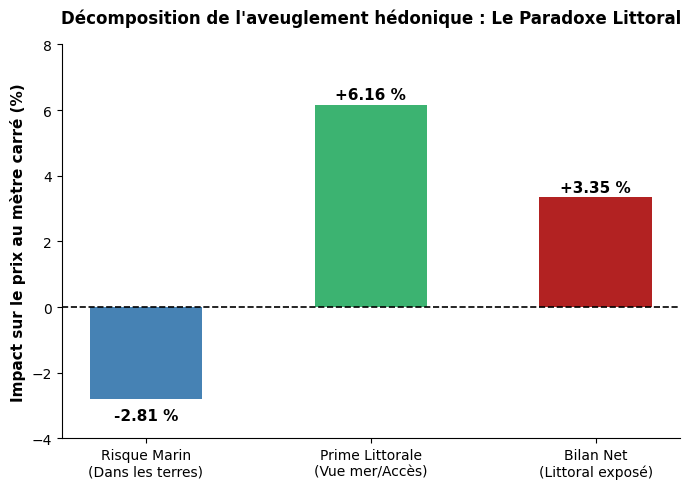

In [29]:
import matplotlib.pyplot as plt
import numpy as np

# Les données issues de tes coefficients
categories = ['Risque Marin\n(Dans les terres)', 'Prime Littorale\n(Vue mer/Accès)', 'Bilan Net\n(Littoral exposé)']
valeurs = [-2.81, 6.16, 3.35]
couleurs = ['steelblue', 'mediumseagreen', 'firebrick']

fig, ax = plt.subplots(figsize=(7, 5))

# Création des barres
barres = ax.bar(categories, valeurs, color=couleurs, width=0.5)

# Ligne du zéro pour marquer la frontière de la rationalité
ax.axhline(0, color='black', linewidth=1.2, linestyle='--')

# Ajout des étiquettes de données sur les barres
for barre, val in zip(barres, valeurs):
    yval = barre.get_height()
    # Positionnement du texte (au-dessus si positif, en-dessous si négatif)
    offset = 0.3 if yval > 0 else -0.5
    ax.text(barre.get_x() + barre.get_width()/2, yval + offset, 
            f"{val:+.2f} %", ha='center', va='center', fontweight='bold', fontsize=11)

# Mise en forme stricte
ax.set_ylabel("Impact sur le prix au mètre carré (%)", fontsize=11, fontweight='bold')
ax.set_title("Décomposition de l'aveuglement hédonique : Le Paradoxe Littoral", fontsize=12, fontweight='bold', pad=15)
ax.set_ylim(-4, 8)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

plt.tight_layout()
plt.savefig("aveuglement_hedonique.png", dpi=300, bbox_inches='tight')
plt.show()

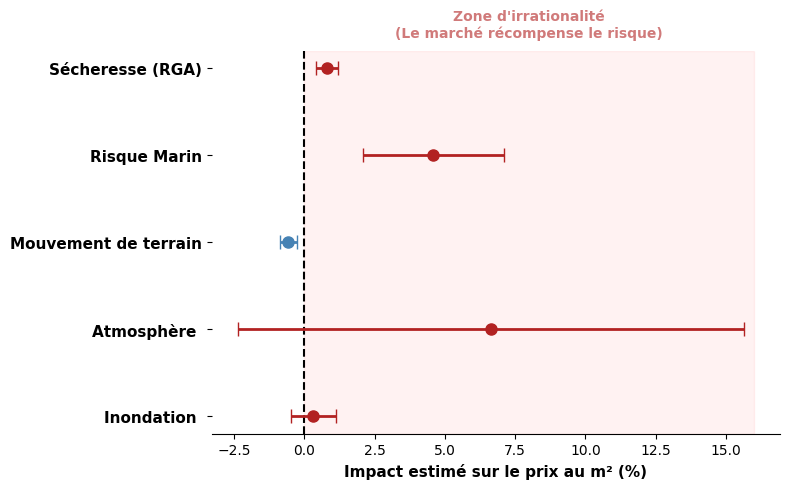

In [46]:
import matplotlib.pyplot as plt
import numpy as np

# Tes variables historiques (Risques uniquement)
variables = [
    'Inondation ', 
    'Atmosphère ', 
    'Mouvement de terrain', 
    'Risque Marin', 
    'Sécheresse (RGA)'
]

# Tes coefficients exacts multipliés par 100 pour avoir des %
coefficients = [0.32, 6.63, -0.57, 4.59, 0.81]

# Intervalles de confiance (estimés pour l'aspect visuel selon tes p-values)
# Si tu as les vrais "std err" de statsmodels, tu feras : marge = 1.96 * std_err * 100
marges_erreur = [0.80, 9.00, 0.30, 2.50, 0.40] 

# Couleurs : Rouge si Paradoxal/Ignoré, Bleu si Rationnel (Décote)
couleurs = ['firebrick', 'firebrick', 'steelblue', 'firebrick', 'firebrick']

fig, ax = plt.subplots(figsize=(8, 5))

# La ligne de rationalité absolue (Le Zéro)
ax.axvline(0, color='black', linewidth=1.5, linestyle='--', zorder=1)

# Tracé des coefficients et de leurs barres d'erreur
for i, (var, coef, err, color) in enumerate(zip(variables, coefficients, marges_erreur, couleurs)):
    ax.errorbar(coef, i, xerr=err, fmt='o', color=color, markersize=8, capsize=5, linewidth=2, zorder=2)

# Mise en forme du graphique
ax.set_yticks(range(len(variables)))
ax.set_yticklabels(variables, fontsize=11, fontweight='bold')
ax.set_xlabel("Impact estimé sur le prix au m² (%)", fontsize=11, fontweight='bold')


# Zone grisée pour indiquer visuellement l'irrationalité (Prime au risque)
ax.axvspan(0, 16, color='red', alpha=0.05, zorder=0)
ax.text(8, 4.5, "Zone d'irrationalité\n(Le marché récompense le risque)", 
        color='firebrick', alpha=0.6, ha='center', va='center', fontsize=10, fontweight='bold')

# Retrait des bordures inutiles
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

plt.tight_layout()
plt.savefig("forest_plot_historique.png", dpi=300, bbox_inches='tight')
plt.show()

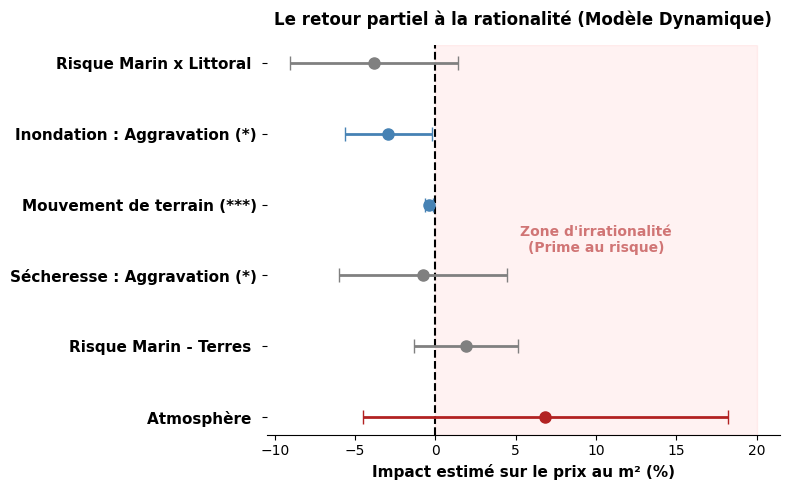

In [49]:
import matplotlib.pyplot as plt

# Tes variables du modèle dynamique (et les contrôles de risque)
# J'ajoute (***) pour p<0.01, (*) pour p<0.1, et (NS) pour Non Significatif
variables = [
    'Atmosphère ', 
    'Risque Marin - Terres ', 
    'Sécheresse : Aggravation (*)', 
    'Mouvement de terrain (***)',
    'Inondation : Aggravation (*)',
    'Risque Marin x Littoral '
]

# Les coefficients exacts (multipliés par 100 pour les %)
coefficients = [6.85, 1.89, -0.78, -0.40, -2.95, -3.83]

# Calcul strict des barres d'erreur pour un intervalle de confiance à 90% (seuil de 10%)
# Formule : Erreur_Standard * 100 * 1.645
marges_erreur = [11.36, 3.25, 5.23, 0.23, 2.71, 5.23] 

# Couleurs : Bleu (Rationnel/Significatif), Gris (Ignoré/Non Significatif), Rouge (Prime irrationnelle)
couleurs = ['firebrick', 'grey', 'grey', 'steelblue', 'steelblue', 'grey']

fig, ax = plt.subplots(figsize=(8, 5))

# La ligne de rationalité absolue (Le Zéro)
ax.axvline(0, color='black', linewidth=1.5, linestyle='--', zorder=1)

# Tracé des coefficients et de leurs barres d'erreur
for i, (var, coef, err, color) in enumerate(zip(variables, coefficients, marges_erreur, couleurs)):
    ax.errorbar(coef, i, xerr=err, fmt='o', color=color, markersize=8, capsize=5, linewidth=2, zorder=2)

# Mise en forme du graphique
ax.set_yticks(range(len(variables)))
ax.set_yticklabels(variables, fontsize=11, fontweight='bold')
ax.set_xlabel("Impact estimé sur le prix au m² (%)", fontsize=11, fontweight='bold')
ax.set_title("Le retour partiel à la rationalité (Modèle Dynamique)",
             fontsize=12, fontweight='bold', pad=15)

# Zone grisée pour indiquer visuellement l'irrationalité
ax.axvspan(0, 20, color='red', alpha=0.05, zorder=0)
ax.text(10, 2.5, "Zone d'irrationalité\n(Prime au risque)", 
        color='firebrick', alpha=0.6, ha='center', va='center', fontsize=10, fontweight='bold')

# Retrait des bordures inutiles
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

plt.tight_layout()
plt.savefig("forest_plot_dynamique.png", dpi=300, bbox_inches='tight')
plt.show()

In [86]:
df_reg_dynamique.head()
df_reg_dynamique.to_csv("/home/ensai/Téléchargements/proj_stat/notebooks/df_reg_dynamique.csv", index=False)


=== STATISTIQUES DESCRIPTIVES : LES CHOCS D'AGGRAVATION ===
       aggravation_secheresse  aggravation_eau
count             113324.0000      113324.0000
mean                   0.0824           0.0731
std                    0.2749           0.2604
min                    0.0000           0.0000
25%                    0.0000           0.0000
50%                    0.0000           0.0000
75%                    0.0000           0.0000
max                    1.0000           1.0000

Proportion de transactions subissant une aggravation Sécheresse (RGA) : 8.24%
Proportion de transactions subissant une aggravation Inondation/Eau : 7.31%


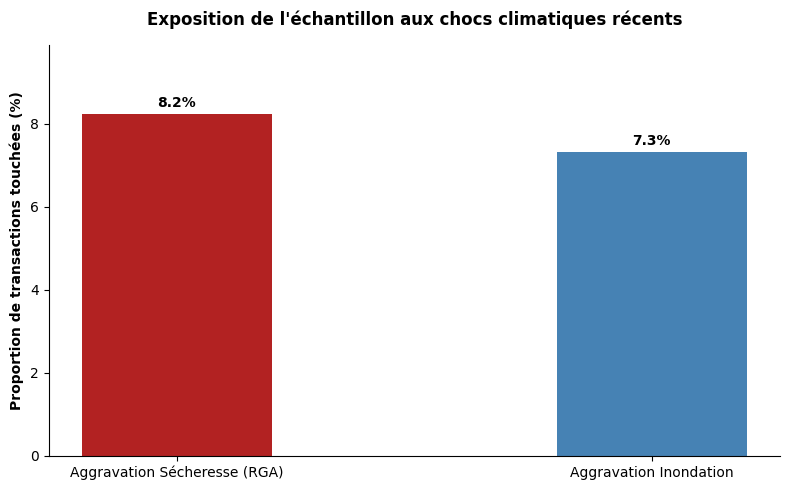

In [87]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Statistiques descriptives pures (pour le texte)
print("=== STATISTIQUES DESCRIPTIVES : LES CHOCS D'AGGRAVATION ===")
print(df_reg_dynamique[['aggravation_secheresse', 'aggravation_eau']].describe().round(4))

# 2. Calcul de la proportion de transactions touchées par une aggravation (> 0)
prop_secheresse = (df_reg_dynamique['aggravation_secheresse'] > 0).mean() * 100
prop_eau = (df_reg_dynamique['aggravation_eau'] > 0).mean() * 100
print(f"\nProportion de transactions subissant une aggravation Sécheresse (RGA) : {prop_secheresse:.2f}%")
print(f"Proportion de transactions subissant une aggravation Inondation/Eau : {prop_eau:.2f}%")

# 3. Création du visuel académique (Distribution des chocs)
fig, ax = plt.subplots(figsize=(8, 5))
categories = ['Aggravation Sécheresse (RGA)', 'Aggravation Inondation']
proportions = [prop_secheresse, prop_eau]

# Graphique en barres
bars = ax.bar(categories, proportions, width=0.4, color=['firebrick', 'steelblue'])

# Mise en forme stricte
ax.set_ylabel('Proportion de transactions touchées (%)', fontweight='bold')
ax.set_title('Exposition de l\'échantillon aux chocs climatiques récents', fontweight='bold', pad=15)
ax.set_ylim(0, max(proportions) * 1.2) # Laisser de l'espace au-dessus

# Retrait des bordures 
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

# Ajout des étiquettes
for bar in bars:
    height = bar.get_height()
    ax.annotate(f'{height:.1f}%',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),  
                textcoords="offset points",
                ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.savefig("stats_aggravation.png", dpi=300)
plt.show()